In [1]:
# to setup the project
import os, pickle
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from implicit.als import AlternatingLeastSquares
from scipy.stats import wilcoxon



# import sys
# print("Python:", sys.executable)

BASE  = r'C:\Users\Tabi\OneDrive - Victoria University of Wellington - STUDENT\Desktop\AIML339\Project\data'
triplets_chunks = pd.read_csv(
    "train_triplets.txt.gz",
    sep="\t",
    header=None,
    names=["user_id", "song_id", "play_count"],
    compression="gzip",
    chunksize=100_000
)

for chunk in triplets_chunks:
    print(chunk.shape)

CACHE = os.path.join(BASE, 'cache')
os.makedirs(CACHE, exist_ok=True)

# the Content features 
features = pd.read_csv(os.path.join(CACHE, 'Content_features.csv'))
assert len(features) == 10000, f"features has {len(features)} rows, expected 10000"
print(f"features: {len(features)} rows")

# interactions
interactions = pd.read_csv(os.path.join(CACHE, 'interactions.csv'))
assert len(interactions) > 700_000, f"interactions only {len(interactions)} rows — reload!"
print(f"interactions: {len(interactions):,} rows")

# the track metadata
import sqlite3
con = sqlite3.connect(os.path.join(BASE, 'raw', 'track_metadata.db'))
allmeta = pd.read_sql("SELECT track_id, song_id, title, artist_name FROM songs", con)
con.close()
print(f"allmeta: {len(allmeta):,} rows")

triplets_path = r'C:\Users\Tabi\OneDrive - Victoria University of Wellington - STUDENT\Desktop\AIML339\Project\data\raw\train_triplets.txt\train_triplets.txt'

# triplets_path = pd.read_csv(os.path.join(CACHE, 'triplets.txt'))

# makign the feature matrix
continuous_features = ['tempo', 'loudness', 'duration'] + [
    c for c in features.columns if c.startswith(('timbre_', 'pitch_'))
]
categorical_features = ['key', 'mode', 'time_signature']

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())]), continuous_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
        categorical_features),
])
X = preprocessor.fit_transform(features).astype(np.float32)
song_id_to_row = {sid: i for i, sid in enumerate(features['song_id'])}
print(f"X matrix: {X.shape}")

# print("\nsetup complete — features, interactions, allmeta, X, song_id_to_row ready")

(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100000, 3)
(100

## Content model

In [2]:
# the number of songs and the number of columns in the features 
print("Number of songs:", len(features))
print("Number of columns:", len(features.columns))


continuous_features = [
    'tempo',
    'loudness',
    'duration'
]

# Add all timbre and pitch summary features
continuous_features += [c for c in features.columns if c.startswith('timbre_') or c.startswith('pitch_')]

categorical_features = ['key','mode','time_signature']


# preprocess
numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('onehot', OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

preprocessor = ColumnTransformer([(
        'numeric',
        numeric_pipeline,
        continuous_features
    ),
    (
        'categorical',
        categorical_pipeline,
        categorical_features
    )
])


# Transform songs into feature vectors
X = preprocessor.fit_transform(features)

X = np.asarray(X, dtype=np.float32) ## storing as float32 bcause of memmory

# print the shape
print("Final feature matrix shape:", X.shape)


# lookign up the song id
song_id_to_row = {song_id: row for row, song_id in enumerate(features['song_id'])}

# Content recommender function:

def recommend_content(user_history, k=10):
    # Keep only songs that exist in the content catalogue
    history = user_history[user_history['song_id'].isin(song_id_to_row)].copy()

    if len(history) == 0:
        return []

    # Get corresponding rows in the song-feature matrix
    played_rows = [song_id_to_row[song_id] for song_id in history['song_id']]

    # Transform play counts so extremely high counts do not dominate
    weights = np.log1p(history['play_count'].to_numpy())

    # Create weighted user profile
    user_profile = np.average(X[played_rows],axis=0,weights=weights)

    # Calculate cosine similarity between user profile and all songs
    scores = cosine_similarity(user_profile.reshape(1, -1),X).flatten()

    # Do not recommend songs already listened to
    scores[played_rows] = -np.inf

    # Select top-k songs
    top_indices = np.argsort(scores)[::-1][:k]

    return [(features.iloc[i]['song_id'], float(scores[i])) for i in top_indices]

Number of songs: 10000
Number of columns: 56
Final feature matrix shape: (10000, 71)


In [3]:
## Evaluation
import numpy as np

# per-user train/test split
# we will do this for each user with enough plays in the subset, we will hide the test_frac from their songs
def user_train_val_test_split(interactions, catalog_set, train_frac=0.6, val_frac=0.2, min_plays=5, seed=42):
    rng = np.random.default_rng(seed)
    in_cat = interactions[interactions['song_id'].isin(catalog_set)]
    train, val, test = {}, {}, {}
    for user, grp in in_cat.groupby('userid'):
        if len(grp) < min_plays:
            continue
        grp = grp.sample(frac=1.0, random_state=seed)
        n = len(grp)
        n_train = int(n * train_frac)
        n_val   = int(n * val_frac)
        train[user] = grp.iloc[:n_train]
        val[user]   = set(grp.iloc[n_train:n_train+n_val]['song_id'])
        test[user]  = set(grp.iloc[n_train+n_val:]['song_id'])
    return train, val, test

# metric definitions
def precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    hits = sum(1 for s in rec_k if s in relevant)
    return hits / k

def recall_at_k(recommended, relevant, k):
    if not relevant:
        return 0.0
    rec_k = recommended[:k]
    hits = sum(1 for s in rec_k if s in relevant)
    return hits / len(relevant)

def ndcg_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    dcg = sum(1/np.log2(i+2) for i, s in enumerate(rec_k) if s in relevant)
    ideal = sum(1/np.log2(i+2) for i in range(min(len(relevant), k)))
    return dcg/ideal if ideal > 0 else 0.0

def diversity_at_k(recommended, k, X, song_id_to_row):
    rec_k = [s for s in recommended[:k] if s in song_id_to_row]
    if len(rec_k) < 2:
        return 0.0
    rows = [song_id_to_row[s] for s in rec_k]
    vecs = X[rows]
    
    sims = cosine_similarity(vecs)
    n = len(rows)
    # average pairwise dissimilarity (upper triangle only)
    total = sum(1 - sims[i, j] for i in range(n) for j in range(i+1, n))
    return total / (n*(n-1)/2)

# evaluation loop
# for each user, we build recommendations form their train songs (recommend content) 
# and score the ranked list against their test songs (the hidden set)
# we will average the metric across ever user and return a dictionary of the means
def evaluate_content(train, test, k=10, sample_users=300, seed=42):
    rng = np.random.default_rng(seed)
    users = list(test)
    if sample_users and len(users) > sample_users:
        users = list(rng.choice(users, size=sample_users, replace=False))
    p, r, n, d = [], [], [], []
    for user in test:
        played = train[user]
        recs = recommend_content(played, k=k)
        if len(recs) == 0:
            continue
        
        ranked = [song_id for song_id, score in recs]
        relevant = test[user]
        p.append(precision_at_k(ranked, relevant, k))
        r.append(recall_at_k(ranked, relevant, k))
        n.append(ndcg_at_k(ranked, relevant, k))
        d.append(diversity_at_k(ranked, k, X, song_id_to_row))
    
    return {'precision': np.mean(p), 'recall': np.mean(r),
            'ndcg': np.mean(n), 'diversity': np.mean(d)}

In [4]:
train, val, test = user_train_val_test_split(interactions, set(features['song_id']))
print(f"{len(test)} evaluable users")
# print(evaluate_content(train, test, k=10))

22840 evaluable users


In [5]:
# sanity check: for a sample of users, can the model even see their test songs?
sample = list(test)[:200]
possible = 0
for u in sample:
    # test songs that ARE in the content catalogue (should be all of them)
    catalog_test = test[u] & set(features['song_id'])
    if catalog_test:
        possible += 1
print(f"{possible}/{len(sample)} users have test songs that exist in the 10k catalogue")

# and: what does a typical user's train size look like?
sizes = [len(train[u]) for u in sample]
print("median train songs per user:", np.median(sizes))

200/200 users have test songs that exist in the 10k catalogue
median train songs per user: 3.0


In [7]:
# print(evaluate_content(train, test, k=10, sample_users=None))

## Collaborative Filtering model

In [6]:

# only the sampled CF users' train interactions
train_pairs = {(u, s) for u, grp in train.items() for s in grp['song_id']}


shared_users = set(train.keys())

keep = []
reader = pd.read_csv(triplets_path, sep='\t', names=['userid','song_id','play_count'],
                     chunksize=2_000_000)
for chunk in reader:
    keep.append(chunk[chunk['userid'].isin(shared_users)])
cf_data = pd.concat(keep, ignore_index=True)

# hide BOTH val and test from CF training
holdout_pairs = {(u, s) for u, songs in val.items()  for s in songs} | \
                {(u, s) for u, songs in test.items() for s in songs}
pair_idx = pd.MultiIndex.from_arrays([cf_data['userid'], cf_data['song_id']])
cf_data = cf_data[~pair_idx.isin(holdout_pairs)].reset_index(drop=True)

# verify the data is clean, and no leakage occurs
chk = pd.MultiIndex.from_arrays([cf_data['userid'], cf_data['song_id']])
print("remaining leaks:", chk.isin(holdout_pairs).sum())
print(f"{len(cf_data):,} CF training interactions across {cf_data['song_id'].nunique():,} songs")

remaining leaks: 0
5,388,978 CF training interactions across 256,059 songs


In [7]:
user_ids = cf_data['userid'].unique()
song_ids = cf_data['song_id'].unique()
user_to_idx = {u:i for i,u in enumerate(user_ids)}
song_to_idx = {s:i for i,s in enumerate(song_ids)}
idx_to_song = {i:s for s,i in song_to_idx.items()}
cf_data['u'] = cf_data['userid'].map(user_to_idx)
cf_data['s'] = cf_data['song_id'].map(song_to_idx)
cf_data['confidence'] = np.log1p(cf_data['play_count'])

matrix = csr_matrix((cf_data['confidence'], (cf_data['u'], cf_data['s'])),
                    shape=(len(user_ids), len(song_ids)))
model = AlternatingLeastSquares(factors=64, regularization=0.05,
                                iterations=15, alpha=15, random_state=42)
model.fit(matrix)
print("ALS retrained on train-only")

c:\Users\Tabi\AppData\Local\Programs\Orange\Lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 16 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


  0%|          | 0/15 [00:00<?, ?it/s]

ALS retrained on train-only


In [8]:
catalog = [s for s in features['song_id'] if s in song_to_idx]
catalog_set = set(catalog)
features_cat = features[features['song_id'].isin(catalog_set)].reset_index(drop=True)
catalog = [s for s in features_cat['song_id'] if s in song_to_idx]
catalog_set = set(catalog)
X = preprocessor.fit_transform(features_cat).astype(np.float32)   # refit on catalogue only
song_id_to_row = {s: i for i, s in enumerate(features_cat['song_id'])}
print(f"final catalogue: {len(catalog)} songs")

# content must use the same set — refilter features, rebuild X and lookup
features_cat = features_cat[features_cat['song_id'].isin(catalog_set)].reset_index(drop=True)
X = preprocessor.fit_transform(features_cat).astype(np.float32)
song_id_to_row = {s: i for i, s in enumerate(features_cat['song_id'])}

# and CF catalogue columns from the same set
# cf_catalog_songs = catalog
cf_catalog_cols  = np.array([song_to_idx[s] for s in catalog])
print(f"content X: {X.shape} | CF catalogue: {len(catalog)}")

final catalogue: 2547 songs
content X: (2547, 71) | CF catalogue: 2547


In [9]:
train, val, test = user_train_val_test_split(interactions, catalog_set,
                                             train_frac=0.6, val_frac=0.2,
                                             min_plays=5, seed=42)
print(f"evaluable users: {len(test):,}")

evaluable users: 22,694


In [11]:
def recommend_als(userid, k=10, train=None):
    if userid not in user_to_idx:
        return []
    uidx = user_to_idx[userid]
    scores = model.item_factors @ model.user_factors[uidx]
    cat_scores = scores[cf_catalog_cols].copy()
    # exclude songs the user already played (from train history)
    if train is not None and userid in train:
        played = set(train[userid]['song_id'])
        for j, sid in enumerate(cf_catalog_songs):
            if sid in played:
                cat_scores[j] = -np.inf
    top = np.argsort(cat_scores)[::-1][:k]
    return [(cf_catalog_songs[i], float(cat_scores[i])) for i in top]

def evaluate_als(test, k=10, sample_users=500, seed=42, train=None):
    rng = np.random.default_rng(seed)
    evaluateUsers = [u for u in test if u in user_to_idx]
    if sample_users and len(evaluateUsers) > sample_users:
        evaluateUsers = list(rng.choice(evaluateUsers, size=sample_users, replace=False))
    p, r, n, d = [], [], [], []
    for user in evaluateUsers:
        recs = recommend_als(user, k=k, train=train)
        if not recs:
            continue
        ranked = [sid for sid, _ in recs]
        relevant = test[user]
        p.append(precision_at_k(ranked, relevant, k))
        r.append(recall_at_k(ranked, relevant, k))
        n.append(ndcg_at_k(ranked, relevant, k))
        d.append(diversity_at_k(ranked, k, X, song_id_to_row))
    # if not p:
    #     return {'precision':0,'recall':0,'ndcg':0,'diversity':0,'n_users':0}
    return {'precision':np.mean(p),'recall':np.mean(r),
            'ndcg':np.mean(n),'diversity':np.mean(d),'n_users':len(p)}

In [12]:
# definitive catalogue = songs in both content features AND retrained CF
catalog = [s for s in features_cat['song_id'] if s in song_to_idx]
catalog_set = set(catalog)
features_cat = features_cat[features_cat['song_id'].isin(catalog_set)].reset_index(drop=True)
X = preprocessor.fit_transform(features_cat).astype(np.float32)
song_id_to_row = {s:i for i,s in enumerate(features_cat['song_id'])}
cf_catalog_songs = catalog
cf_catalog_cols  = np.array([song_to_idx[s] for s in cf_catalog_songs])
print(f"catalogue: {len(catalog)} songs | X: {X.shape}")
# ALSScore = evaluate_als(test, k=10, sample_users=500)
# print("Content:", evaluate_content(train, test, k=10, sample_users=500))
# print("ALS: ", ALSScore)

catalogue: 2547 songs | X: (2547, 71)


In [15]:
# # build a set of (user, song) test pairs to remove
# test_pairs = {(u, s) for u, songs in test.items() for s in songs}

# # fast vectorised removal — build a boolean mask without apply
# pair_index = pd.MultiIndex.from_arrays([cf_data['userid'], cf_data['song_id']])
# mask = ~pair_index.isin(test_pairs)
# before = len(cf_data)
# cf_data = cf_data[mask].reset_index(drop=True)
# print(f"removed {before - len(cf_data)} test interactions")

# # verify it's actually clean now
# check_pairs = pd.MultiIndex.from_arrays([cf_data['userid'], cf_data['song_id']])
# print(f"remaining leaks: {check_pairs.isin(test_pairs).sum()}")   # MUST be 0a

In [16]:
# AlsScore = evaluate_als(test, k=10, sample_users=500)

# print("ALS (clean):", AlsScore)

## Hybrid model

In [14]:
## helper functions
# content score: cosine similarity between user's profile and ONE song
def content_score(userid, song_id, train):
    if userid not in train or song_id not in song_id_to_row:
        return 0.0
    history = train[userid]
    history = history[history['song_id'].isin(song_id_to_row)]
    if len(history) == 0:
        return 0.0
    rows = [song_id_to_row[s] for s in history['song_id']]
    weights = np.log1p(history['play_count'].to_numpy())
    profile = np.average(X[rows], axis=0, weights=weights)
    song_vec = X[song_id_to_row[song_id]]
    # cosine similarity between profile and this one song
    return float(np.dot(profile, song_vec) /
                 (np.linalg.norm(profile)*np.linalg.norm(song_vec) + 1e-9))

# CF score: ALS dot product for one user→one song
def cf_score(userid, song_id):
    if userid not in user_to_idx or song_id not in song_to_idx:
        return 0.0
    u = model.user_factors[user_to_idx[userid]]
    v = model.item_factors[song_to_idx[song_id]]
    return float(np.dot(u, v))

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


def buildHybridData(users, label_source, train, n_neg=5, seed=42):
    rng = np.random.default_rng(seed)
    rows, labels = [], []
    catalog_arr = np.array(catalog)

    for user in users:
        if user not in train:
            continue

        hist_size = len(train[user])
        train_songs = set(train[user]['song_id'])
        positive_songs = set(label_source.get(user, set())) & catalog_set
        if len(positive_songs) == 0:
            continue

        # positives
        for song in positive_songs:
            cs = content_score(user, song, train)
            fs = cf_score(user, song)
            if not np.isfinite(cs) or not np.isfinite(fs):
                continue
            rows.append([cs, fs, hist_size, hist_size * fs])
            labels.append(1)

        # negatives
        played = train_songs | positive_songs
        negative_candidates = catalog_arr[~np.isin(catalog_arr, list(played))]
        num_negatives = min(n_neg * len(positive_songs), len(negative_candidates))
        if num_negatives == 0:
            continue
        sampled_negatives = rng.choice(negative_candidates, size=num_negatives, replace=False)

        for song in sampled_negatives:
            cs = content_score(user, song, train)
            fs = cf_score(user, song)
            if not np.isfinite(cs) or not np.isfinite(fs):
                continue
            rows.append([cs, fs, hist_size, hist_size * fs])
            labels.append(0)

    return np.asarray(rows, dtype=np.float32), np.asarray(labels, dtype=np.int32)

In [16]:
# train the fusion model on VAL
XHybrid, yHybrid = buildHybridData(list(val.keys()), val, train, n_neg=5)
print(f"{len(yHybrid)} examples, {yHybrid.mean():.1%} positive")

hybridScaler = StandardScaler()
XHybrid_scaled = hybridScaler.fit_transform(XHybrid)
hybridModel = LogisticRegression(max_iter=1000, class_weight='balanced')
hybridModel.fit(XHybrid_scaled, yHybrid)

print("learned weights:")
for name, w in zip(['content', 'cf', 'history', 'historyxcf'], hybridModel.coef_[0]):
    print(f"{name}: {w:+.3f}")

151824 examples, 16.7% positive
learned weights:
content: +0.184
cf: +4.401
history: -0.073
historyxcf: -0.621


In [17]:
def recommend_hybrid(userid, k=10, train=None):
    if userid not in user_to_idx or userid not in train:
        return []
    hist_size = len(train[userid])
    played = set(train[userid]['song_id'])

    # build features for every catalogue song, then score with hybridModel
    feats = []
    for song in catalog:
        cs = content_score(userid, song, train)
        fs = cf_score(userid, song)
        feats.append([cs, fs, hist_size, hist_size * fs])
    feats = np.array(feats, dtype=np.float32)

    feats_scaled = hybridScaler.transform(feats)
    probs = hybridModel.predict_proba(feats_scaled)[:, 1]   # P(like)

    # exclude already-played, then top-k
    for j, song in enumerate(catalog):
        if song in played:
            probs[j] = -np.inf
    top = np.argsort(probs)[::-1][:k]
    return [(catalog[i], float(probs[i])) for i in top]

In [18]:
def evaluate_hybrid(test, k=10, sample_users=500, seed=42, train=None):
    rng = np.random.default_rng(seed)
    eval_users = [u for u in test if u in user_to_idx and u in train]
    if sample_users and len(eval_users) > sample_users:
        eval_users = list(rng.choice(eval_users, size=sample_users, replace=False))
    p, r, n, d = [], [], [], []
    for user in eval_users:
        recs = recommend_hybrid(user, k=k, train=train)
        if not recs: continue
        ranked = [sid for sid,_ in recs]
        relevant = test[user]
        p.append(precision_at_k(ranked, relevant, k))
        r.append(recall_at_k(ranked, relevant, k))
        n.append(ndcg_at_k(ranked, relevant, k))
        d.append(diversity_at_k(ranked, k, X, song_id_to_row))
    return {'precision':np.mean(p),'recall':np.mean(r),
            'ndcg':np.mean(n),'diversity':np.mean(d),'n_users':len(p)}



# print("HYBRID:", evaluate_hybrid(test, k=10, sample_users=500, train=train))

In [22]:
# re-run on a different user sample to check stability
# print(evaluate_hybrid(test, k=10, sample_users=500, seed=99, train=train))
# print(evaluate_als(test, k=10, sample_users=500, seed=99, train=train))

In [23]:
# Store the test results:
# contentResults = evaluate_content(test, k=10, sample_users=500, seed=20, train=train)
# cfResults = evaluate_als(test, k=10, sample_users=500, seed=20, train=train)
# hybridResults = evaluate_hybrid(test, k=10, sample_users=500, seed=20, train=train)

In [24]:
# split test users into history-size buckets, evaluate hybrid vs ALS in each
buckets = {'sparse (5-10)': [], 'medium (11-30)': [], 'rich (31+)': []}
for u in test:
    if u not in train: continue
    h = len(train[u])
    if h <= 10: buckets['sparse (5-10)'].append(u)
    elif h <= 30: buckets['medium (11-30)'].append(u)
    else: buckets['rich (31+)'].append(u)

for name, users in buckets.items():
    sample = users[:300]
    # build a mini-test dict for just these users
    sub_test = {u: test[u] for u in sample}
    h = evaluate_hybrid(sub_test, k=10, sample_users=None, train=train)
    a = evaluate_als(sub_test, k=10, sample_users=None, train=train)
    print(f"{name:16s} n={len(sample):4d} | hybrid nDCG {h['ndcg']:.3f} vs ALS {a['ndcg']:.3f}")

sparse (5-10)    n= 300 | hybrid nDCG 0.285 vs ALS 0.284
medium (11-30)   n= 113 | hybrid nDCG 0.312 vs ALS 0.310
rich (31+)       n=   0 | hybrid nDCG nan vs ALS nan


c:\Users\Tabi\AppData\Local\Programs\Orange\Lib\site-packages\numpy\core\fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
c:\Users\Tabi\AppData\Local\Programs\Orange\Lib\site-packages\numpy\core\_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


## For demos, and for fun

In [25]:
# helper: find a song by (partial) name -> its song_id
def find_song(name):
    m = allmeta[allmeta['title'].str.contains(name, case=False, na=False)]
    m = m[m['song_id'].isin(catalog_set)]   # must be in our catalogue
    if len(m) == 0:
        print(f"No catalogue song matching '{name}'")
        return None
    row = m.iloc[0]
    print(f"Matched: {row['title']} — {row['artist_name']}  ({row['song_id']})")
    return row['song_id']

# pretty-print a recommendation list
def show(recs, label):
    print(f"\n{label}:")
    if not recs:
        print("  (no recommendations)")
        return
    for i, (sid, score) in enumerate(recs, 1):
        meta = allmeta[allmeta['song_id'] == sid]
        title = f"{meta.iloc[0]['title']} — {meta.iloc[0]['artist_name']}" if len(meta) else sid
        print(f"  {i}. {title}   ({score:.3f})")

In [27]:
allmeta[allmeta['song_id'].isin(catalog_set)].sample(20)

,track_id,song_id,title,artist_name
432888,TRABTXS128F92E2FDC,SOSQIQU12A8C143A53,Ammonite,Zeromancer
440839,TRAASFP128F42980BD,SOFSKON12A8C13B3B5,Illuminate,Orbital
262293,TRBDIMX128F147A307,SOKWISB12A6D4F8861,Puzzle of Hearts,Sergio Mendes
450768,TRAJAGW128EF3664E1,SOMBWDW12A6D4F7248,Soorma,Jazzy B
428948,TRAHKUS128F425ABD8,SOLXJZP12A8C1352AE,In The Name Of God (Gentle Revolution Album Ve...,Scott Krippayne
262128,TRBDFUU128F92EF5BC,SONXFYD12AAA8C6D44,Execution,First Blood
443504,TRAPNQZ128F145B04E,SONCWSL12A6D4F419D,Let's Lock The Door (And Throw Away The Key),Jay & The Americans
447047,TRAUXSK128F427C58D,SOBMWTE12A8C13C2AF,The Modern Rome Burning,Anti-Flag
450622,TRAJZCH128F933D2B7,SOSNQCC12AB0185B62,Patricia,Mighty Mighty Bosstones
453593,TRAVFJV128F92D2043,SOKWNWI12A8C13383F,Bianca's Midnight Lullaby,Al Di Meola


In [33]:
def demo_from_song(song_name, k=5):
    sid = find_song(song_name)
    if sid is None:
        return
    # treat the single song as a one-song history
    fake_history = pd.DataFrame({'song_id': [sid], 'play_count': [1]})
    show(recommend_content(fake_history, k=k), "The content-based model recommends:")

demo_from_song("Ammonite", k=5)

Matched: Ammonite — Zeromancer  (SOSQIQU12A8C143A53)

The content-based model recommends::
  1. Goodness & Mercy — Ini Kamoze   (0.757)
  2. Hustlin' — D.O.W.N.   (0.696)
  3. Ji Xiang Yan Chu — Dylan Kuo   (0.675)
  4. Crass Commercialism — Black Flag   (0.669)
  5. Intro — 40 Grit   (0.656)


In [61]:
# function to find the songs of the artists in the data

def songs_by_artist(name):
    m = allmeta[allmeta['artist_name'].str.contains(name, case=False, na=False)]
    m = m[m['song_id'].isin(catalog_set)]          # catalogue only
    if len(m) == 0:
        print(f"No catalogue songs for an artist matching '{name}'")
        return
    print(f"{len(m)} catalogue song(s) for '{name}':")
    for _, row in m.iterrows():
        print(f"  {row['title']} — {row['artist_name']}   ({row['song_id']})")

songs_by_artist("Bob Dylan")

2 catalogue song(s) for 'Bob Dylan':
  New Pony — Bob Dylan   (SOJGCRU12A8C1323B7)
  Simple Twist Of Fate — Bob Dylan   (SOBMWXO12A8C132120)


In [ ]:
## function to find the 

def in_catalogue(name):
    """Search the catalogue by (partial) song title, case-insensitive."""
    m = allmeta[allmeta['title'].str.contains(name, case=False, na=False)]
    m = m[m['song_id'].isin(catalog_set)]        # restrict to the shared catalogue
    if len(m) == 0:
        print(f"'{name}' is NOT in the catalogue")
        return
    print(f"{len(m)} match(es) for '{name}':")
    for _, row in m.iterrows():
        print(f"  {row['title']} — {row['artist_name']}   ({row['song_id']})")

# examples
in_catalogue("Here Comes The Sun")
# in_catalogue("Mr. Brightside")

In [62]:
def demo_from_song(song_name, k=5):
    sid = find_song(song_name)
    if sid is None:
        return

    # find a user in the model who actually played this song
    fans = [u for u in train
            if u in user_to_idx and sid in set(train[u]['song_id'])]
    if not fans:
        print("No user in the model has this song in their history — try another.")
        return

    user = fans[0]
    hist = train[user]
    print(f"\nRecommending for a listener with this song in their history "
          f"({len(hist)} songs played)\n")

    show(recommend_content(hist, k=k),"Content")
    show(recommend_als(user, k=k, train=train), "Collaborative filtering")
    show(recommend_hybrid(user, k=k, train=train),"Hybrid model")

demo_from_song("Simple Twist Of Fate", k=7)

Matched: Simple Twist Of Fate — Bob Dylan  (SOBMWXO12A8C132120)

Recommending for a listener with this song in their history (4 songs played)


Content:
  1. Yippiyo-Ay — The Presets   (0.674)
  2. Ernesto Nazareth — Laurindo Almeida / Carlos Barbosa-Lima / Charlie Byrd   (0.627)
  3. Les Amours de Nathalie — Les Malpolis   (0.611)
  4. Intro — The Germs   (0.607)
  5. In The Name of the Father — Adr Lavey   (0.581)
  6. El Arte De Amar — Gabinete Caligari   (0.569)
  7. Nassau Town — John D. Loudermilk   (0.559)

Collaborative filtering:
  1. From The Ritz To The Rubble — Arctic Monkeys   (0.965)
  2. Infected — Bad Religion   (0.458)
  3. Eriatarka — The Mars Volta   (0.435)
  4. Dig Up Her Bones — The Misfits   (0.428)
  5. Blue Orchid — The White Stripes   (0.416)
  6. Korea (LP Version) — Deftones   (0.405)
  7. Firestarter — The Prodigy   (0.397)

Hybrid model:
  1. From The Ritz To The Rubble — Arctic Monkeys   (1.000)
  2. Infected — Bad Religion   (0.999)
  3. Eriatarka — The 

In [54]:
# build a title lookup ONCE (not inside any loop)
title_map = dict(zip(allmeta['song_id'], allmeta['title']))

def richest_users(n=10):
    rows = []
    for u in train:
        if u not in user_to_idx:
            continue
        hist = train[u]
        in_cat = hist[hist['song_id'].isin(catalog_set)]
        if len(in_cat) == 0:
            continue
        top = in_cat.sort_values('play_count', ascending=False).iloc[0]
        name = title_map.get(top['song_id'], top['song_id'])   # dict lookup, instant
        rows.append((u, len(in_cat), name, int(top['play_count'])))
    rows.sort(key=lambda r: r[1], reverse=True)
    print(f"{'catalogue songs':>15} | top seed song (plays)")
    for u, n_cat, name, pc in rows[:n]:
        print(f"{n_cat:>15} | {name} ({pc} plays)   [user {u[:8]}...]")
    return rows[:n]

top_users = richest_users(50)

catalogue songs | top seed song (plays)
             27 | Hey Sexy Lady (73 plays)   [user c1255748...]
             27 | Lead Me To The Cross (Acoustic) (1 plays)   [user ec6dfcf1...]
             22 | Check On It (12 plays)   [user 73875900...]
             22 | Marea De Venus (4 plays)   [user d964fc03...]
             22 | One I Love (19 plays)   [user db6a78c7...]
             21 | Slaves & Bulldozers (12 plays)   [user 4e73d9e0...]
             19 | Everyone's At It (16 plays)   [user 119b7c88...]
             18 | Revitalise (8 plays)   [user 736083bd...]
             18 | In My Hood (Explicit Album Version) (10 plays)   [user cbc7bddb...]
             17 | Everyone's At It (3 plays)   [user 3584ec93...]
             17 | Baby's On Fire (26 plays)   [user b7c24f77...]
             15 | Die Kunst der Fuge_ BWV 1080 (2007 Digital Remaster): Contrapunctus XVII - Inversus (5 plays)   [user 2b3e6030...]
             15 | Romantic Rights (9 plays)   [user 33a12864...]
             15 

## Performing repeated evaluations:

In [ ]:
import numpy as np
def repeated_eval(eval_fn, test, n_runs=5, k=10, sample_users=1000, **kw):
    runs = [eval_fn(test, k=k, sample_users=sample_users, seed=s, **kw)
            for s in range(n_runs)]
    out = {}
    for m in ['precision','recall','ndcg','diversity']:
        vals = [r[m] for r in runs]
        out[m] = (np.mean(vals), np.std(vals))
    return out, runs

content_stats, content_runs = repeated_eval(evaluate_content, test, train=train)
als_stats,als_runs = repeated_eval(evaluate_als, test, train=train)
hybrid_stats,hybrid_runs  = repeated_eval(evaluate_hybrid, test, train=train)

## Performing a statistical test
# The Wilcoxon signed-rank test

In [64]:
print("ALS:", evaluate_als(test, k=10, sample_users=2000, seed=0, train=train))

ALS: {'precision': 0.08155000000000001, 'recall': 0.4696428571428571, 'ndcg': 0.3077929045352305, 'diversity': 0.9121115034559293, 'n_users': 2000}


In [ ]:
# results block, — matched users, repeated runs, paired tests

# fix one evaluation user set, used everywhere
rng = np.random.default_rng(0)
candidates = [u for u in test if u in user_to_idx and u in train]
EVAL_USERS = list(rng.choice(candidates, size=min(2000, len(candidates)), replace=False))
print(f"evaluating on {len(EVAL_USERS)} matched users\n")

# per-user nDCG for one model, over a given user list 
def per_user_ndcg(kind, users, k=10):
    out = {}
    for u in users:
        if kind == 'content':
            recs = recommend_content(train[u], k=k)
        elif kind == 'als':
            recs = recommend_als(u, k=k, train=train)
        else:  # hybrid
            recs = recommend_hybrid(u, k=k, train=train)
        if recs:
            out[u] = ndcg_at_k([s for s, _ in recs], test[u], k)
    return out

# compute once per model on the matched set
cont_n = per_user_ndcg('content', EVAL_USERS)
als_n  = per_user_ndcg('als',     EVAL_USERS)
hyb_n  = per_user_ndcg('hybrid',  EVAL_USERS)

# users all three produced recs for (true paired set)
common = [u for u in EVAL_USERS if u in cont_n and u in als_n and u in hyb_n]
print(f"paired users (all three models): {len(common)}\n")

c = np.array([cont_n[u] for u in common])
a = np.array([als_n[u]  for u in common])
h = np.array([hyb_n[u]  for u in common])

# --- mean +/- std of per-user nDCG ---
print("mean nDCG@10 (per-user, matched):")
print(f"  content: {c.mean():.4f} +/- {c.std():.4f}")
print(f"  Collaborative Filtering:     {a.mean():.4f} +/- {a.std():.4f}")
print(f"  hybrid:  {h.mean():.4f} +/- {h.std():.4f}\n")

# paired Wilcoxon tests 
# ALS vs content
stat1, p1 = wilcoxon(a, c)
print(f"ALS vs content : p={p1:.2e} | median diff={np.median(a-c):+.4f}")
# hybrid vs ALS
stat2, p2 = wilcoxon(h, a)
print(f"hybrid vs ALS  : p={p2:.4f} | median diff={np.median(h-a):+.4f}")

# Bonferroni note: 2 comparisons -> adjusted threshold 0.05/2 = 0.025
print("\n(Bonferroni-adjusted threshold for 2 tests: 0.025)")

evaluating on 2000 matched users



KeyboardInterrupt: 

## Evaluating model complexity and computation power

In [20]:
import time

# ALS training time
t0 = time.time()
model.fit(matrix)
print(f"ALS training: {time.time()-t0:.1f} s")

# fusion training time
t0 = time.time()
hybridModel.fit(XHybrid_scaled, yHybrid)
print(f"Hybrid training: {time.time()-t0:.2f} s")

# model sizes (parameter counts)
n_users, n_songs = matrix.shape
factors = model.factors
als_params = (n_users + n_songs) * factors
print(f"ALS parameters: {als_params:,}  ({n_users:,} users + {n_songs:,} songs) x {factors} factors")
print(f"Hybrid parameters: {len(hybridModel.coef_[0]) + 1}  (4 weights + 1 bias)")

  0%|          | 0/15 [00:00<?, ?it/s]

ALS training: 30.4 s
Hybrid training: 0.26 s
ALS parameters: 17,849,536  (22,840 users + 256,059 songs) x 64 factors
Hybrid parameters: 5  (4 weights + 1 bias)


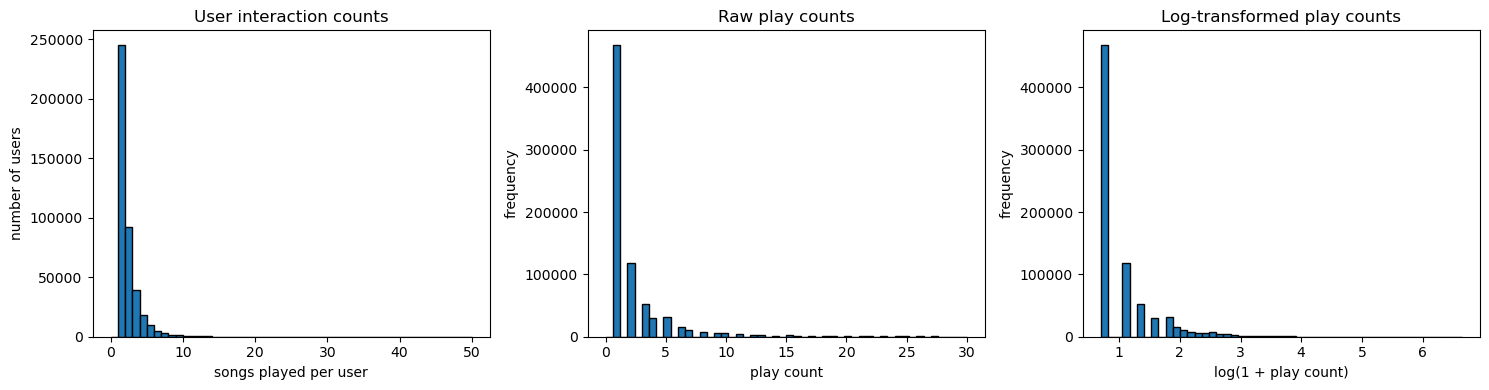

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. interactions per user (the sparsity story)
user_counts = interactions.groupby('userid').size()
axes[0].hist(user_counts, bins=50, range=(0, 50), edgecolor='black')
axes[0].set_xlabel('songs played per user')
axes[0].set_ylabel('number of users')
axes[0].set_title('User interaction counts')

# 2a. raw play counts (skew)
axes[1].hist(interactions['play_count'], bins=50, range=(0, 30), edgecolor='black')
axes[1].set_xlabel('play count')
axes[1].set_ylabel('frequency')
axes[1].set_title('Raw play counts')

# 2b. log-transformed (why the transform helps)
axes[2].hist(np.log1p(interactions['play_count']), bins=50, edgecolor='black')
axes[2].set_xlabel('log(1 + play count)')
axes[2].set_ylabel('frequency')
axes[2].set_title('Log-transformed play counts')

plt.tight_layout()
plt.savefig('data_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

Sample of catalogue songs:
                                         title             artist_name
                            Syvä meri (Oceano)              Kari Tapio
                       Intensity In Ten Cities         Embrace the End
                                I'll Be Around            Frank Ifield
                            Clementina Santafè                Gloriana
                           Groovin' With Jimmy             Jimmy Burns
                                 Sweet To Mama            Frank Stokes
                  Hope  (Edited Album Version) Twista Featuring Cee-Lo
                        Boat Day At the Marina               Forensics
                          Miss Ohio's Nameless                    Why?
The Little Stack Of Barley / Cronin's Hornpipe            Séamus Ennis
                          Jesus Is Coming Soon    Blind Willie Johnson
                                           Sex             Bow Wow Wow
                                 Crescent Moon    

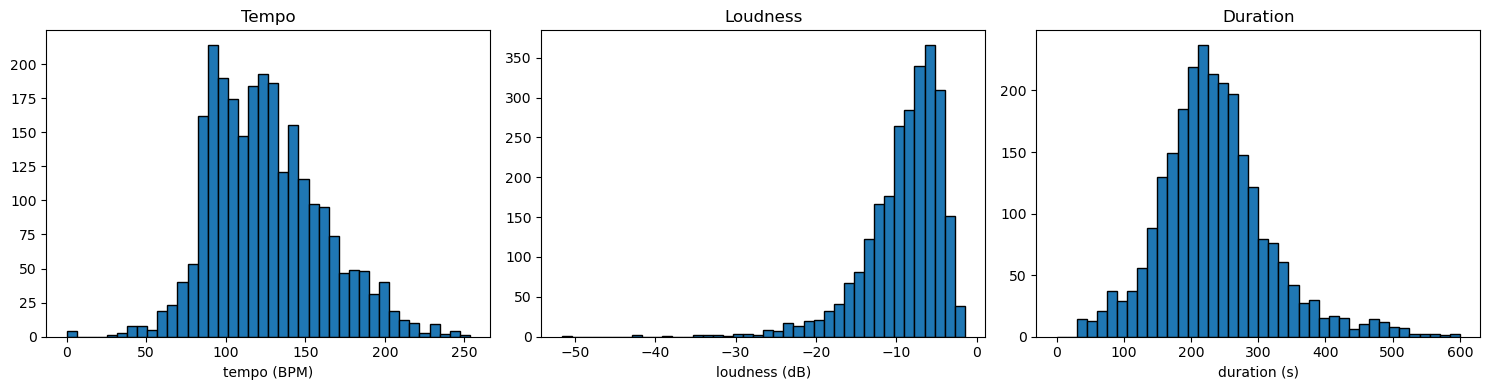

In [13]:
import matplotlib.pyplot as plt

# restrict metadata to the catalogue, join to features
cat_meta = allmeta[allmeta['song_id'].isin(set(features['song_id']))]
cat_feat = features_cat   # already the catalogue's features

# 1. a readable sample of what's actually in there
print("Sample of catalogue songs:")
print(cat_meta[['title','artist_name']].sample(15, random_state=1).to_string(index=False))

# 2. most common artists in the catalogue
print("\nMost represented artists:")
print(cat_meta['artist_name'].value_counts().head(10).to_string())

# 3. audio-feature distributions of the CATALOGUE songs
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(cat_feat['tempo'], bins=40, edgecolor='black')
axes[0].set_xlabel('tempo (BPM)'); axes[0].set_title('Tempo')
axes[1].hist(cat_feat['loudness'], bins=40, edgecolor='black')
axes[1].set_xlabel('loudness (dB)'); axes[1].set_title('Loudness')
axes[2].hist(cat_feat['duration'], bins=40, range=(0,600), edgecolor='black')
axes[2].set_xlabel('duration (s)'); axes[2].set_title('Duration')
plt.tight_layout()
plt.savefig('catalogue_features.png', dpi=150, bbox_inches='tight')
plt.show()